# Brain connectivity from diffusion MRI + a dementia model on OASIS
Prototype pipeline. Imaging: Stanford HARDI (one healthy subject, via DIPY). Tabular: OASIS longitudinal (Kaggle). Lesions are **simulated**; the imaging and tabular data come from different people and are not linked.

## 0. Setup

In [2]:
!pip install dipy --only-binary=:all: -q
import sys, dipy
print("Python:", sys.version.split()[0])
print("DIPY  :", dipy.__version__)

Python: 3.13.18
DIPY  : 1.12.1


## 1. Load the diffusion data and the atlas

In [3]:
import os, glob, json
import numpy as np
import matplotlib.pyplot as plt

from dipy.data import get_fnames, default_sphere
from dipy.io.image import load_nifti
from dipy.io.gradients import read_bvals_bvecs
from dipy.core.gradients import gradient_table

OUT = "/kaggle/working"
os.makedirs(f"{OUT}/figures", exist_ok=True)

hardi_fname, hardi_bval, hardi_bvec = get_fnames(name="stanford_hardi")
label_fname = get_fnames(name="stanford_labels")

data, affine = load_nifti(hardi_fname)
labels, _ = load_nifti(label_fname)
labels = labels.astype(int)
bvals, bvecs = read_bvals_bvecs(hardi_bval, hardi_bvec)
gtab = gradient_table(bvals, bvecs=bvecs)

print("dMRI shape:", data.shape)
print("Labels shape:", labels.shape)
print("Volumes:", len(bvals), "| b-values:", np.unique(bvals.round(-2)))
print("Atlas regions:", len(np.unique(labels)) - 1)

[2026-11-24 05:24:26][dipy] INFO: Creating new folder /root/.dipy/stanford_hardi
[2026-11-24 05:24:26][dipy] INFO: Downloading "HARDI150.nii.gz" to /root/.dipy/stanford_hardi
[2026-11-24 05:24:26][dipy] INFO: From: https://stacks.stanford.edu/file/druid:yx282xq2090/dwi.nii.gz


  0%|          | 0/5578 MB [00:00]

[2026-11-24 05:24:51][dipy] INFO: Downloading "HARDI150.bval" to /root/.dipy/stanford_hardi
[2026-11-24 05:24:51][dipy] INFO: From: https://stacks.stanford.edu/file/druid:yx282xq2090/dwi.bvals


  0%|          | 0/1 MB [00:00]

[2026-11-24 05:24:51][dipy] INFO: Downloading "HARDI150.bvec" to /root/.dipy/stanford_hardi
[2026-11-24 05:24:51][dipy] INFO: From: https://stacks.stanford.edu/file/druid:yx282xq2090/dwi.bvecs


  0%|          | 0/1 MB [00:00]

[2026-11-24 05:24:51][dipy] INFO: Files successfully downloaded to /root/.dipy/stanford_hardi
[2026-11-24 05:24:51][dipy] INFO: Downloading "aparc-reduced.nii.gz" to /root/.dipy/stanford_hardi
[2026-11-24 05:24:51][dipy] INFO: From: https://stacks.stanford.edu/file/druid:yx282xq2090/aparc-reduced.nii.gz


  0%|          | 0/4 MB [00:00]

[2026-11-24 05:24:52][dipy] INFO: Downloading "label_info.txt" to /root/.dipy/stanford_hardi
[2026-11-24 05:24:52][dipy] INFO: From: https://stacks.stanford.edu/file/druid:yx282xq2090/label_info.txt


  0%|          | 0/1 MB [00:00]

[2026-11-24 05:24:52][dipy] INFO: Files successfully downloaded to /root/.dipy/stanford_hardi
dMRI shape: (81, 106, 76, 160)
Labels shape: (81, 106, 76)
Volumes: 160 | b-values: [   0. 2000.]
Atlas regions: 86


## 2. Brain mask and diffusion tensor (FA, MD)

In [4]:
from dipy.segment.mask import median_otsu
from dipy.reconst.dti import TensorModel

_, mask = median_otsu(data, vol_idx=range(10, 50), median_radius=3,
                      numpass=1, autocrop=False, dilate=2)

tenfit = TensorModel(gtab).fit(data, mask=mask)
fa = np.nan_to_num(tenfit.fa)
md = np.nan_to_num(tenfit.md)
print("FA range:", fa.min().round(2), fa.max().round(2))

/tmp/ipykernel_50/1801314964.py:4: ArgsDeprecationWarning: "autocrop" was deprecated

* deprecated from version: 1.11.0
* Will raise <class 'dipy.utils.deprecator.ExpiredDeprecationError'> as of version: 1.13.0

  _, mask = median_otsu(data, vol_idx=range(10, 50), median_radius=3,


FA range: 0.0 1.0


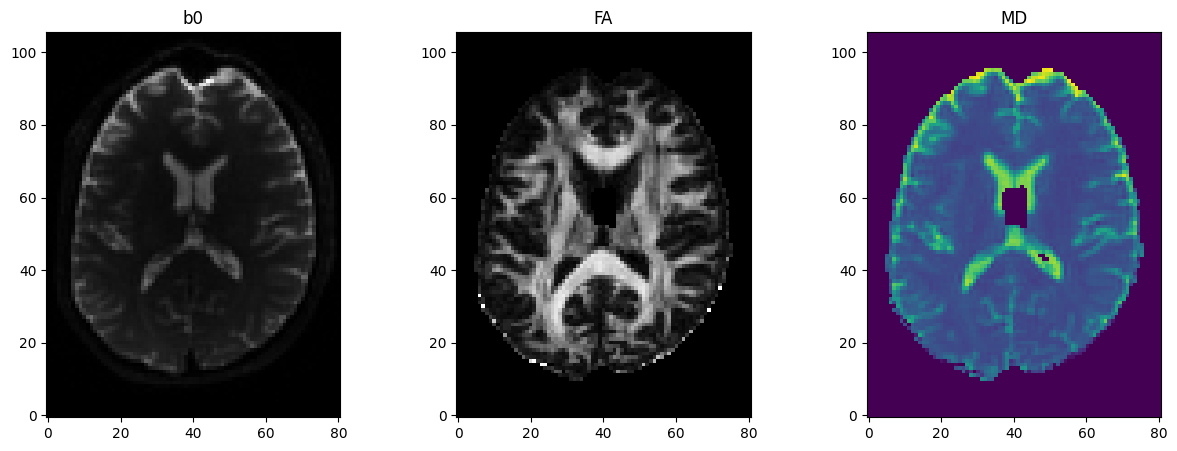

In [5]:
z = data.shape[2] // 2
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(data[:, :, z, 0].T, cmap="gray", origin="lower"); ax[0].set_title("b0")
ax[1].imshow(fa[:, :, z].T, cmap="gray", origin="lower", vmin=0, vmax=1); ax[1].set_title("FA")
ax[2].imshow(md[:, :, z].T, cmap="viridis", origin="lower"); ax[2].set_title("MD")
plt.savefig(f"{OUT}/figures/fa_md.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Tractography
Deterministic tracking from white-matter seeds (FA > 0.2). The slow cell.

In [6]:
from dipy.reconst.shm import CsaOdfModel
from dipy.direction import DeterministicMaximumDirectionGetter
from dipy.tracking.stopping_criterion import ThresholdStoppingCriterion
from dipy.tracking import utils
from dipy.tracking.local_tracking import LocalTracking
from dipy.tracking.streamline import Streamlines, length

white_matter = (fa > 0.2) & mask

csa_fit = CsaOdfModel(gtab, 6).fit(data, mask=white_matter)
dg = DeterministicMaximumDirectionGetter.from_shcoeff(
    csa_fit.shm_coeff, max_angle=30.0, sphere=default_sphere)

stopping = ThresholdStoppingCriterion(fa, 0.2)
seeds = utils.seeds_from_mask(white_matter, affine, density=[1, 1, 1])
print("Seeds:", len(seeds))

streamlines = Streamlines(LocalTracking(dg, stopping, seeds, affine, step_size=0.5))
print("Raw streamlines:", len(streamlines))

Seeds: 77585
Raw streamlines: 173514


In [8]:
MAX_STREAMLINES = 40000
rng = np.random.default_rng(42)

lens = np.array(list(length(streamlines)))
keep = np.where(lens >= 20)[0]                      # at least 20 mm
if len(keep) > MAX_STREAMLINES:
    keep = rng.choice(keep, MAX_STREAMLINES, replace=False)
streamlines = Streamlines([streamlines[i] for i in sorted(keep)])
print("Streamlines kept:", len(streamlines))

Streamlines kept: 40000


## 4. Connectivity matrix and graph metrics

Connectivity matrix: (86, 86) | connections: 1107


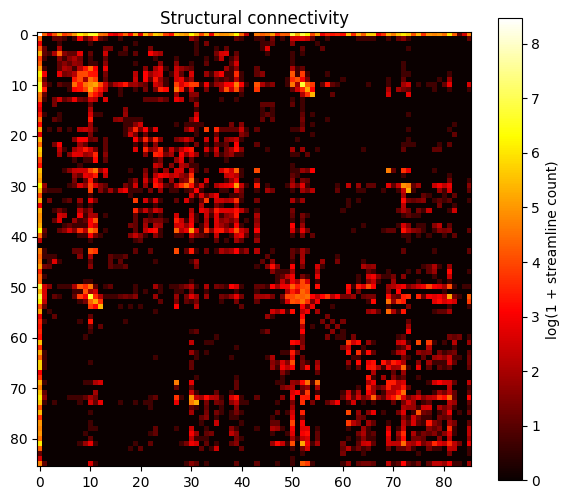

In [9]:
import networkx as nx

M = utils.connectivity_matrix(streamlines, affine, labels, symmetric=True)
M[0, :] = 0; M[:, 0] = 0                            # drop background label
region_ids = np.unique(labels)[1:]
C = M[np.ix_(region_ids, region_ids)].astype(float)
print("Connectivity matrix:", C.shape, "| connections:", int((C > 0).sum() // 2))

plt.figure(figsize=(7, 6))
plt.imshow(np.log1p(C), cmap="hot")
plt.colorbar(label="log(1 + streamline count)")
plt.title("Structural connectivity")
plt.savefig(f"{OUT}/figures/connectivity.png", dpi=150, bbox_inches="tight"); plt.show()

In [10]:
def graph_metrics(C, min_streamlines=3):
    A = (C >= min_streamlines).astype(int)
    np.fill_diagonal(A, 0)
    G = nx.from_numpy_array(A)
    return {
        "node_strength": C.sum(axis=1),
        "global_efficiency": nx.global_efficiency(G),
        "density": nx.density(G),
    }

gm = graph_metrics(C)
print("Global efficiency:", round(gm["global_efficiency"], 3))
print("Density:", round(gm["density"], 3))

Global efficiency: 0.573
Density: 0.173


## 5. Simulated lesions and disconnection
A spherical lesion cuts every streamline that touches it; the matrix is rebuilt from the survivors.

In [12]:
def sphere_mask(shape, center, radius):
    x, y, z = np.ogrid[:shape[0], :shape[1], :shape[2]]
    d2 = (x - center[0])**2 + (y - center[1])**2 + (z - center[2])**2
    return d2 <= radius**2

def lesion_effect(streamlines, affine, labels, region_ids, C_before, center, radius):
    lm = sphere_mask(labels.shape, center, radius)
    survivors = Streamlines(utils.target(streamlines, affine, lm, include=False))
    n_cut = len(streamlines) - len(survivors)

    if len(survivors) == 0:
        return dict(radius=radius, streamlines_cut_pct=100.0,
                    connection_loss_pct=100.0, edges_lost_pct=100.0), lm

    M2 = utils.connectivity_matrix(survivors, affine, labels, symmetric=True)
    M2[0, :] = 0; M2[:, 0] = 0
    C_after = M2[np.ix_(region_ids, region_ids)].astype(float)

    return dict(
        radius=radius,
        streamlines_cut_pct=100 * n_cut / len(streamlines),
        connection_loss_pct=100 * (1 - C_after.sum() / C_before.sum()),
        edges_lost_pct=100 * (((C_before > 0) & (C_after == 0)).sum()
                              / (C_before > 0).sum()),
    ), lm

Lesion center (voxel): (np.int64(39), np.int64(42), np.int64(38)) | smoothed FA there: 0.71
   radius  streamlines_cut_pct  connection_loss_pct  edges_lost_pct
0       2                 1.66                 1.85            1.54
1       4                 5.64                 6.26            7.05
2       6                 8.84                 9.73           11.83
3       8                13.13                14.45           15.67
4      10                18.81                20.57           19.11


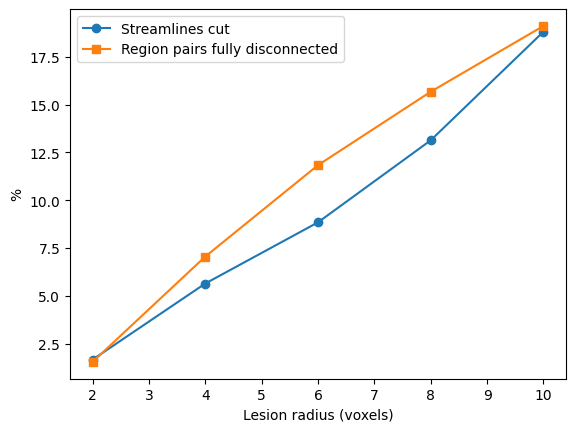

In [13]:
import pandas as pd
from scipy.ndimage import gaussian_filter

fa_smooth = gaussian_filter(fa, sigma=2) * mask
center = np.unravel_index(np.argmax(fa_smooth), fa.shape)
print("Lesion center (voxel):", center, "| smoothed FA there:", fa_smooth[center].round(2))

rows = []
for r in [2, 4, 6, 8, 10]:
    res, lm = lesion_effect(streamlines, affine, labels, region_ids, C, center, r)
    rows.append(res)
lesion_df = pd.DataFrame(rows).round(2)
print(lesion_df)

plt.plot(lesion_df["radius"], lesion_df["streamlines_cut_pct"], "o-", label="Streamlines cut")
plt.plot(lesion_df["radius"], lesion_df["edges_lost_pct"], "s-", label="Region pairs fully disconnected")
plt.xlabel("Lesion radius (voxels)"); plt.ylabel("%"); plt.legend()
plt.savefig(f"{OUT}/figures/lesion_sweep.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Save the imaging outputs used by the Streamlit app
`streamlines_small.trk` (15,000 streamlines) is what the app loads.

In [17]:
import nibabel as nib
from dipy.io.stateful_tractogram import Space, StatefulTractogram
from dipy.io.streamline import save_trk

ref = nib.load(hardi_fname)
sft = StatefulTractogram(streamlines, ref, Space.RASMM)
save_trk(sft, f"{OUT}/streamlines.trk", bbox_valid_check=False)

np.savez_compressed(f"{OUT}/volumes.npz",
                    fa=fa.astype(np.float32), md=md.astype(np.float32),
                    labels=labels.astype(np.int16), affine=affine,
                    mask=mask, C=C, region_ids=region_ids)

lesion_df.to_csv(f"{OUT}/lesion_sweep.csv", index=False)

for f in sorted(os.listdir(OUT)):
    p = os.path.join(OUT, f)
    if os.path.isfile(p):
        print(f, round(os.path.getsize(p) / 1e6, 2), "MB")

lesion_sweep.csv 0.0 MB
streamlines.trk 83.73 MB
volumes.npz 1.41 MB


In [22]:
rng = np.random.default_rng(0)
idx = np.sort(rng.choice(len(streamlines), 15000, replace=False))
small = Streamlines([streamlines[i] for i in idx])
save_trk(StatefulTractogram(small, ref, Space.RASMM),
         f"{OUT}/streamlines_small.trk", bbox_valid_check=False)
print(round(os.path.getsize(f"{OUT}/streamlines_small.trk") / 1e6, 1), "MB")

31.4 MB


## 7. OASIS dementia model
Features are demographics and brain volume only. MMSE and CDR are excluded because the label is defined from them (leakage). Validation is grouped by subject.

In [16]:
!pip install kagglehub -q

import kagglehub, glob, pandas as pd

path = kagglehub.dataset_download("jboysen/mri-and-alzheimers")
print("Downloaded to:", path)

paths = glob.glob(f"{path}/**/*.csv", recursive=True)
print(paths)

csv_path = [p for p in paths if "longitudinal" in p][0]
df = pd.read_csv(csv_path)
print(df.columns.tolist())
print(df["Group"].value_counts())

Downloaded to: /kaggle/input/datasets/jboysen/mri-and-alzheimers
['/kaggle/input/datasets/jboysen/mri-and-alzheimers/oasis_cross-sectional.csv', '/kaggle/input/datasets/jboysen/mri-and-alzheimers/oasis_longitudinal.csv']
['Subject ID', 'MRI ID', 'Group', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']
Group
Nondemented    190
Demented       146
Converted       37
Name: count, dtype: int64


In [18]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_validate

sex_col = "M/F" if "M/F" in df.columns else "Gender"
df["sex"] = (df[sex_col] == "M").astype(int)
df["target"] = (df["Group"] != "Nondemented").astype(int)

features = ["sex", "Age", "EDUC", "SES", "eTIV", "nWBV", "ASF"]
X, y, groups = df[features], df["target"], df["Subject ID"]

model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")),
])
cv = cross_validate(model, X, y, groups=groups, cv=GroupKFold(n_splits=5),
                    scoring=["accuracy", "roc_auc"])
print("Accuracy:", cv["test_accuracy"].mean().round(3), "| ROC-AUC:", cv["test_roc_auc"].mean().round(3))

model.fit(X, y)
imp = {k: float(v) for k, v in zip(features, model.named_steps["rf"].feature_importances_.round(3))}
print(imp)

joblib.dump(model, f"{OUT}/oasis_model.pkl")
json.dump({"features": features, "accuracy": float(cv["test_accuracy"].mean()),
           "roc_auc": float(cv["test_roc_auc"].mean()), "importance": imp},
          open(f"{OUT}/oasis_meta.json", "w"))

Accuracy: 0.63 | ROC-AUC: 0.662
{'sex': 0.05, 'Age': 0.14, 'EDUC': 0.136, 'SES': 0.073, 'eTIV': 0.19, 'nWBV': 0.224, 'ASF': 0.186}


### 7b. Drop the ambiguous *Converted* group (Demented vs Nondemented only)

In [20]:
d2 = df[df["Group"] != "Converted"].copy()
d2["target"] = (d2["Group"] == "Demented").astype(int)
feats2 = ["sex", "Age", "EDUC", "SES", "eTIV", "nWBV"]

m2 = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")),
])
cv2 = cross_validate(m2, d2[feats2], d2["target"], groups=d2["Subject ID"],
                     cv=GroupKFold(n_splits=5), scoring=["accuracy", "roc_auc"])
print("Demented vs Nondemented only")
print("Accuracy:", cv2["test_accuracy"].mean().round(3),
      "| ROC-AUC:", cv2["test_roc_auc"].mean().round(3))

Demented vs Nondemented only
Accuracy: 0.652 | ROC-AUC: 0.701


In [21]:
m2.fit(d2[feats2], d2["target"])
imp2 = {k: float(v) for k, v in zip(feats2, m2.named_steps["rf"].feature_importances_.round(3))}
print(imp2)

joblib.dump(m2, f"{OUT}/oasis_model.pkl")
json.dump({"features": feats2,
           "task": "Demented vs Nondemented (Converted excluded)",
           "n_rows": int(len(d2)),
           "accuracy": float(cv2["test_accuracy"].mean()),
           "roc_auc": float(cv2["test_roc_auc"].mean()),
           "importance": imp2},
          open(f"{OUT}/oasis_meta.json", "w"))
print("saved")

{'sex': 0.065, 'Age': 0.172, 'EDUC': 0.165, 'SES': 0.075, 'eTIV': 0.255, 'nWBV': 0.268}
saved


### 7c. Compare models with repeated grouped cross-validation, then save the final one

In [23]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

def evaluate(model, X, y, groups, seeds=(0, 1, 2, 3, 4)):
    accs, aucs = [], []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        r = cross_validate(model, X, y, groups=groups, cv=cv,
                           scoring=["accuracy", "roc_auc"])
        accs.append(r["test_accuracy"].mean())
        aucs.append(r["test_roc_auc"].mean())
    return np.mean(accs), np.std(accs), np.mean(aucs)

def make(clf):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()), ("clf", clf)])

candidates = {
    "Logistic regression": make(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "SVM (RBF)": make(SVC(probability=True, class_weight="balanced")),
    "Random forest (shallow)": make(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42)),
    "Gradient boosting": make(GradientBoostingClassifier(
        n_estimators=100, max_depth=2, random_state=42)),
}

for name, m in candidates.items():
    acc, sd, auc = evaluate(m, d2[feats2], d2["target"], d2["Subject ID"])
    print(f"{name:25s} acc {acc:.3f} (±{sd:.3f}) | AUC {auc:.3f}")

Logistic regression       acc 0.697 (±0.029) | AUC 0.760
SVM (RBF)                 acc 0.627 (±0.019) | AUC 0.681
Random forest (shallow)   acc 0.636 (±0.022) | AUC 0.685
Gradient boosting         acc 0.616 (±0.017) | AUC 0.670


In [24]:
best = make(LogisticRegression(max_iter=1000, class_weight="balanced"))
best.fit(d2[feats2], d2["target"])

coefs = best.named_steps["clf"].coef_[0]            # on standardized features
signed = {k: float(round(v, 3)) for k, v in zip(feats2, coefs)}
abs_imp = np.abs(coefs) / np.abs(coefs).sum()
imp3 = {k: float(round(v, 3)) for k, v in zip(feats2, abs_imp)}
print("Signed coefficients:", signed)
print("Relative importance:", imp3)

acc, sd, auc = evaluate(best, d2[feats2], d2["target"], d2["Subject ID"])

joblib.dump(best, f"{OUT}/oasis_model.pkl")
json.dump({"features": feats2,
           "model": "Logistic regression (standardized features)",
           "task": "Demented vs Nondemented (Converted excluded)",
           "validation": "5x repeated StratifiedGroupKFold(5), grouped by subject",
           "n_rows": int(len(d2)),
           "accuracy": float(acc), "accuracy_sd": float(sd), "roc_auc": float(auc),
           "coefficients": signed, "importance": imp3},
          open(f"{OUT}/oasis_meta.json", "w"))
print("saved | acc", round(acc, 3), "| AUC", round(auc, 3))

Signed coefficients: {'sex': 0.762, 'Age': -0.64, 'EDUC': -0.752, 'SES': -0.277, 'eTIV': -0.557, 'nWBV': -1.051}
Relative importance: {'sex': 0.189, 'Age': 0.159, 'EDUC': 0.186, 'SES': 0.069, 'eTIV': 0.138, 'nWBV': 0.26}
saved | acc 0.697 | AUC 0.76


## 8. Bundle the files for download

In [25]:
!cd /kaggle/working && zip -r results.zip oasis_model.pkl oasis_meta.json streamlines_small.trk volumes.npz lesion_sweep.csv figures
!ls -lh /kaggle/working/results.zip

  adding: oasis_model.pkl (deflated 43%)
  adding: oasis_meta.json (deflated 39%)
  adding: streamlines_small.trk (deflated 15%)
  adding: volumes.npz (deflated 1%)
  adding: lesion_sweep.csv (deflated 25%)
  adding: figures/ (stored 0%)
  adding: figures/connectivity.png (deflated 12%)
  adding: figures/fa_md.png (deflated 14%)
  adding: figures/lesion_sweep.png (deflated 8%)
-rw-r--r-- 1 root root 28M Nov 24 05:48 /kaggle/working/results.zip
